# **Cell 1 - Mount Google Drive**

In [1]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

Mounted at /content/drive


# **Cell 2 - Path Proyek**

In [2]:
ROOT = Path("/content/drive/MyDrive/Detection Object - Yolo8")

print("Folder ada:", ROOT.exists())
print(*list(ROOT.iterdir()), sep="\n")

Folder ada: True
/content/drive/MyDrive/Detection Object - Yolo8/Tang Rivet
/content/drive/MyDrive/Detection Object - Yolo8/Penggaris Siku 25 CM
/content/drive/MyDrive/Detection Object - Yolo8/notebooks
/content/drive/MyDrive/Detection Object - Yolo8/Water Pass
/content/drive/MyDrive/Detection Object - Yolo8/app
/content/drive/MyDrive/Detection Object - Yolo8/Tekiro C Clamp
/content/drive/MyDrive/Detection Object - Yolo8/docs
/content/drive/MyDrive/Detection Object - Yolo8/Gergaji Kayu
/content/drive/MyDrive/Detection Object - Yolo8/Gergaji Besi
/content/drive/MyDrive/Detection Object - Yolo8/Meteran
/content/drive/MyDrive/Detection Object - Yolo8/Gunting
/content/drive/MyDrive/Detection Object - Yolo8/Gunting Plat
/content/drive/MyDrive/Detection Object - Yolo8/Kunci T
/content/drive/MyDrive/Detection Object - Yolo8/Tang Scun Hidrolik
/content/drive/MyDrive/Detection Object - Yolo8/runs
/content/drive/MyDrive/Detection Object - Yolo8/gallery
/content/drive/MyDrive/Detection Object - Y

# **Cell 3 - Cek dataset**

In [3]:
for split in ["train", "valid", "test"]:
    n_img = len(list((ROOT / split / "images").glob("*.jpg")))
    n_lab = len(list((ROOT / split / "labels").glob("*.txt")))
    print(f"{split:6}  gambar={n_img:3}  label={n_lab:3}")

train   gambar=310  label=310
valid   gambar= 63  label= 63
test    gambar= 22  label= 22


# **Cell 4 - Perbaiki data.yaml**

In [4]:
yaml_path = ROOT / "data.yaml"
yaml_path.write_text(f"""path: {ROOT}
train: train/images
val: valid/images
test: test/images
nc: 11
names: ['gergaji_besi', 'gergaji_kayu', 'gunting', 'gunting_plat', 'kunci_t', 'meteran', 'penggaris_siku', 'tang_rivet', 'tang_scun_hidrolik', 'tekiro_c_clamp', 'water_pass']
""")
print(yaml_path.read_text())

path: /content/drive/MyDrive/Detection Object - Yolo8
train: train/images
val: valid/images
test: test/images
nc: 11
names: ['gergaji_besi', 'gergaji_kayu', 'gunting', 'gunting_plat', 'kunci_t', 'meteran', 'penggaris_siku', 'tang_rivet', 'tang_scun_hidrolik', 'tekiro_c_clamp', 'water_pass']



# **Cell 5 - Install & cek GPU**

In [5]:
%pip install ultralytics -q
import torch
from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "MASIH CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu130
GPU: Tesla T4


# **Cell 6 - Train**

In [6]:
model = YOLO("yolov8n.pt")
model.train(
    data=str(ROOT / "data.yaml"),
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    project=str(ROOT / "runs"),
    name="colab",
)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Detection Object - Yolo8/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=colab-3, nbs=64, nms=None, ops

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  3,  4,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bf37b24eac0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046, 

# **Cell 7- Cek hasil (setelah train selesai)**

best.pt: True


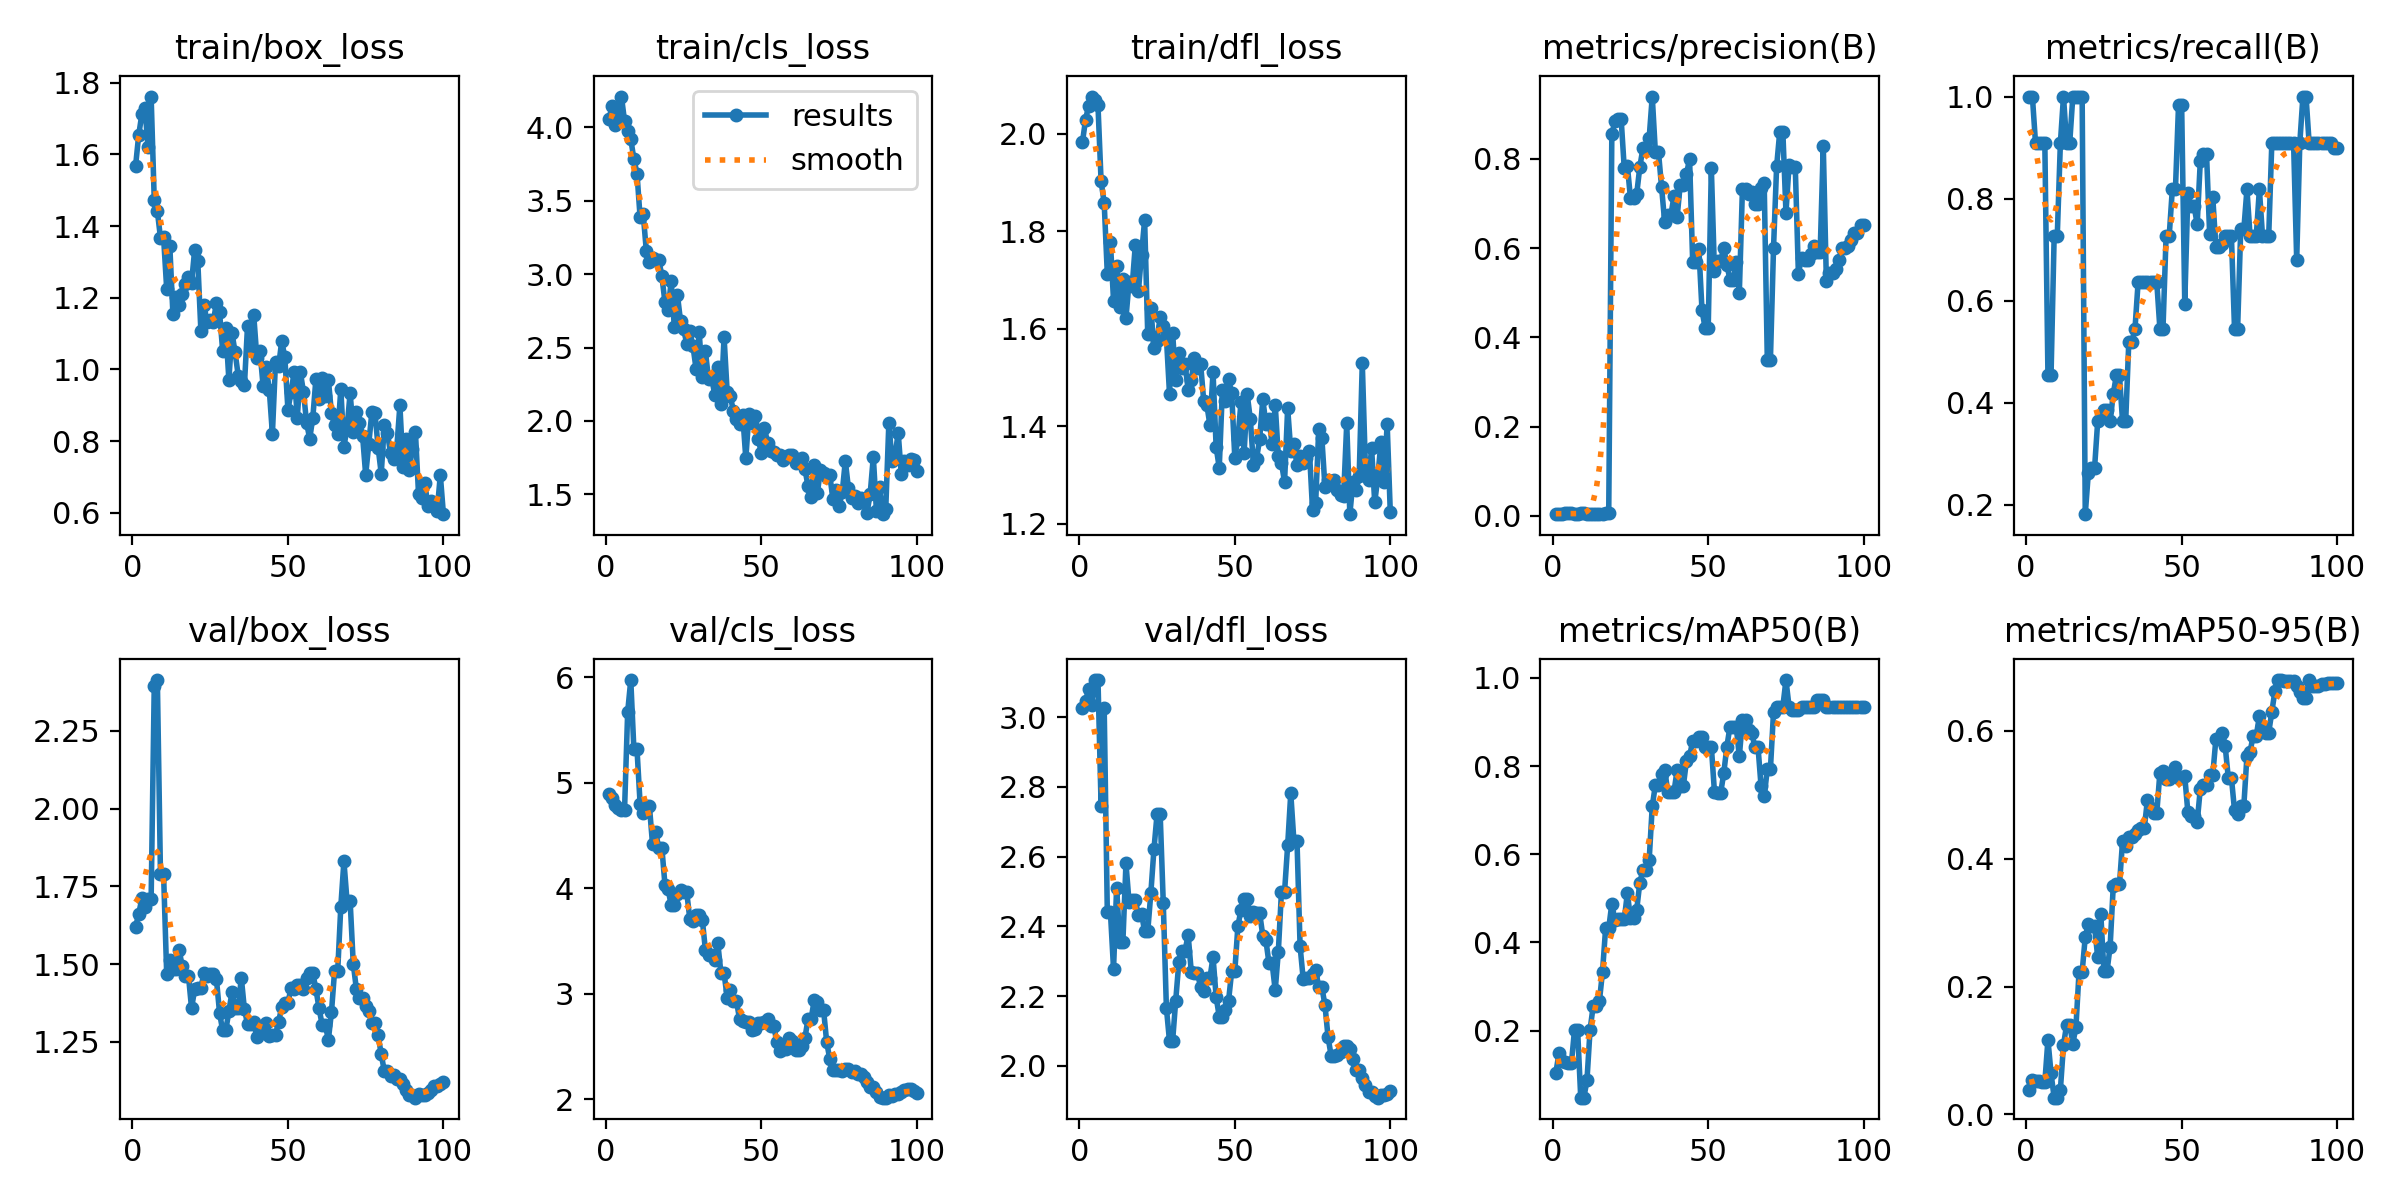

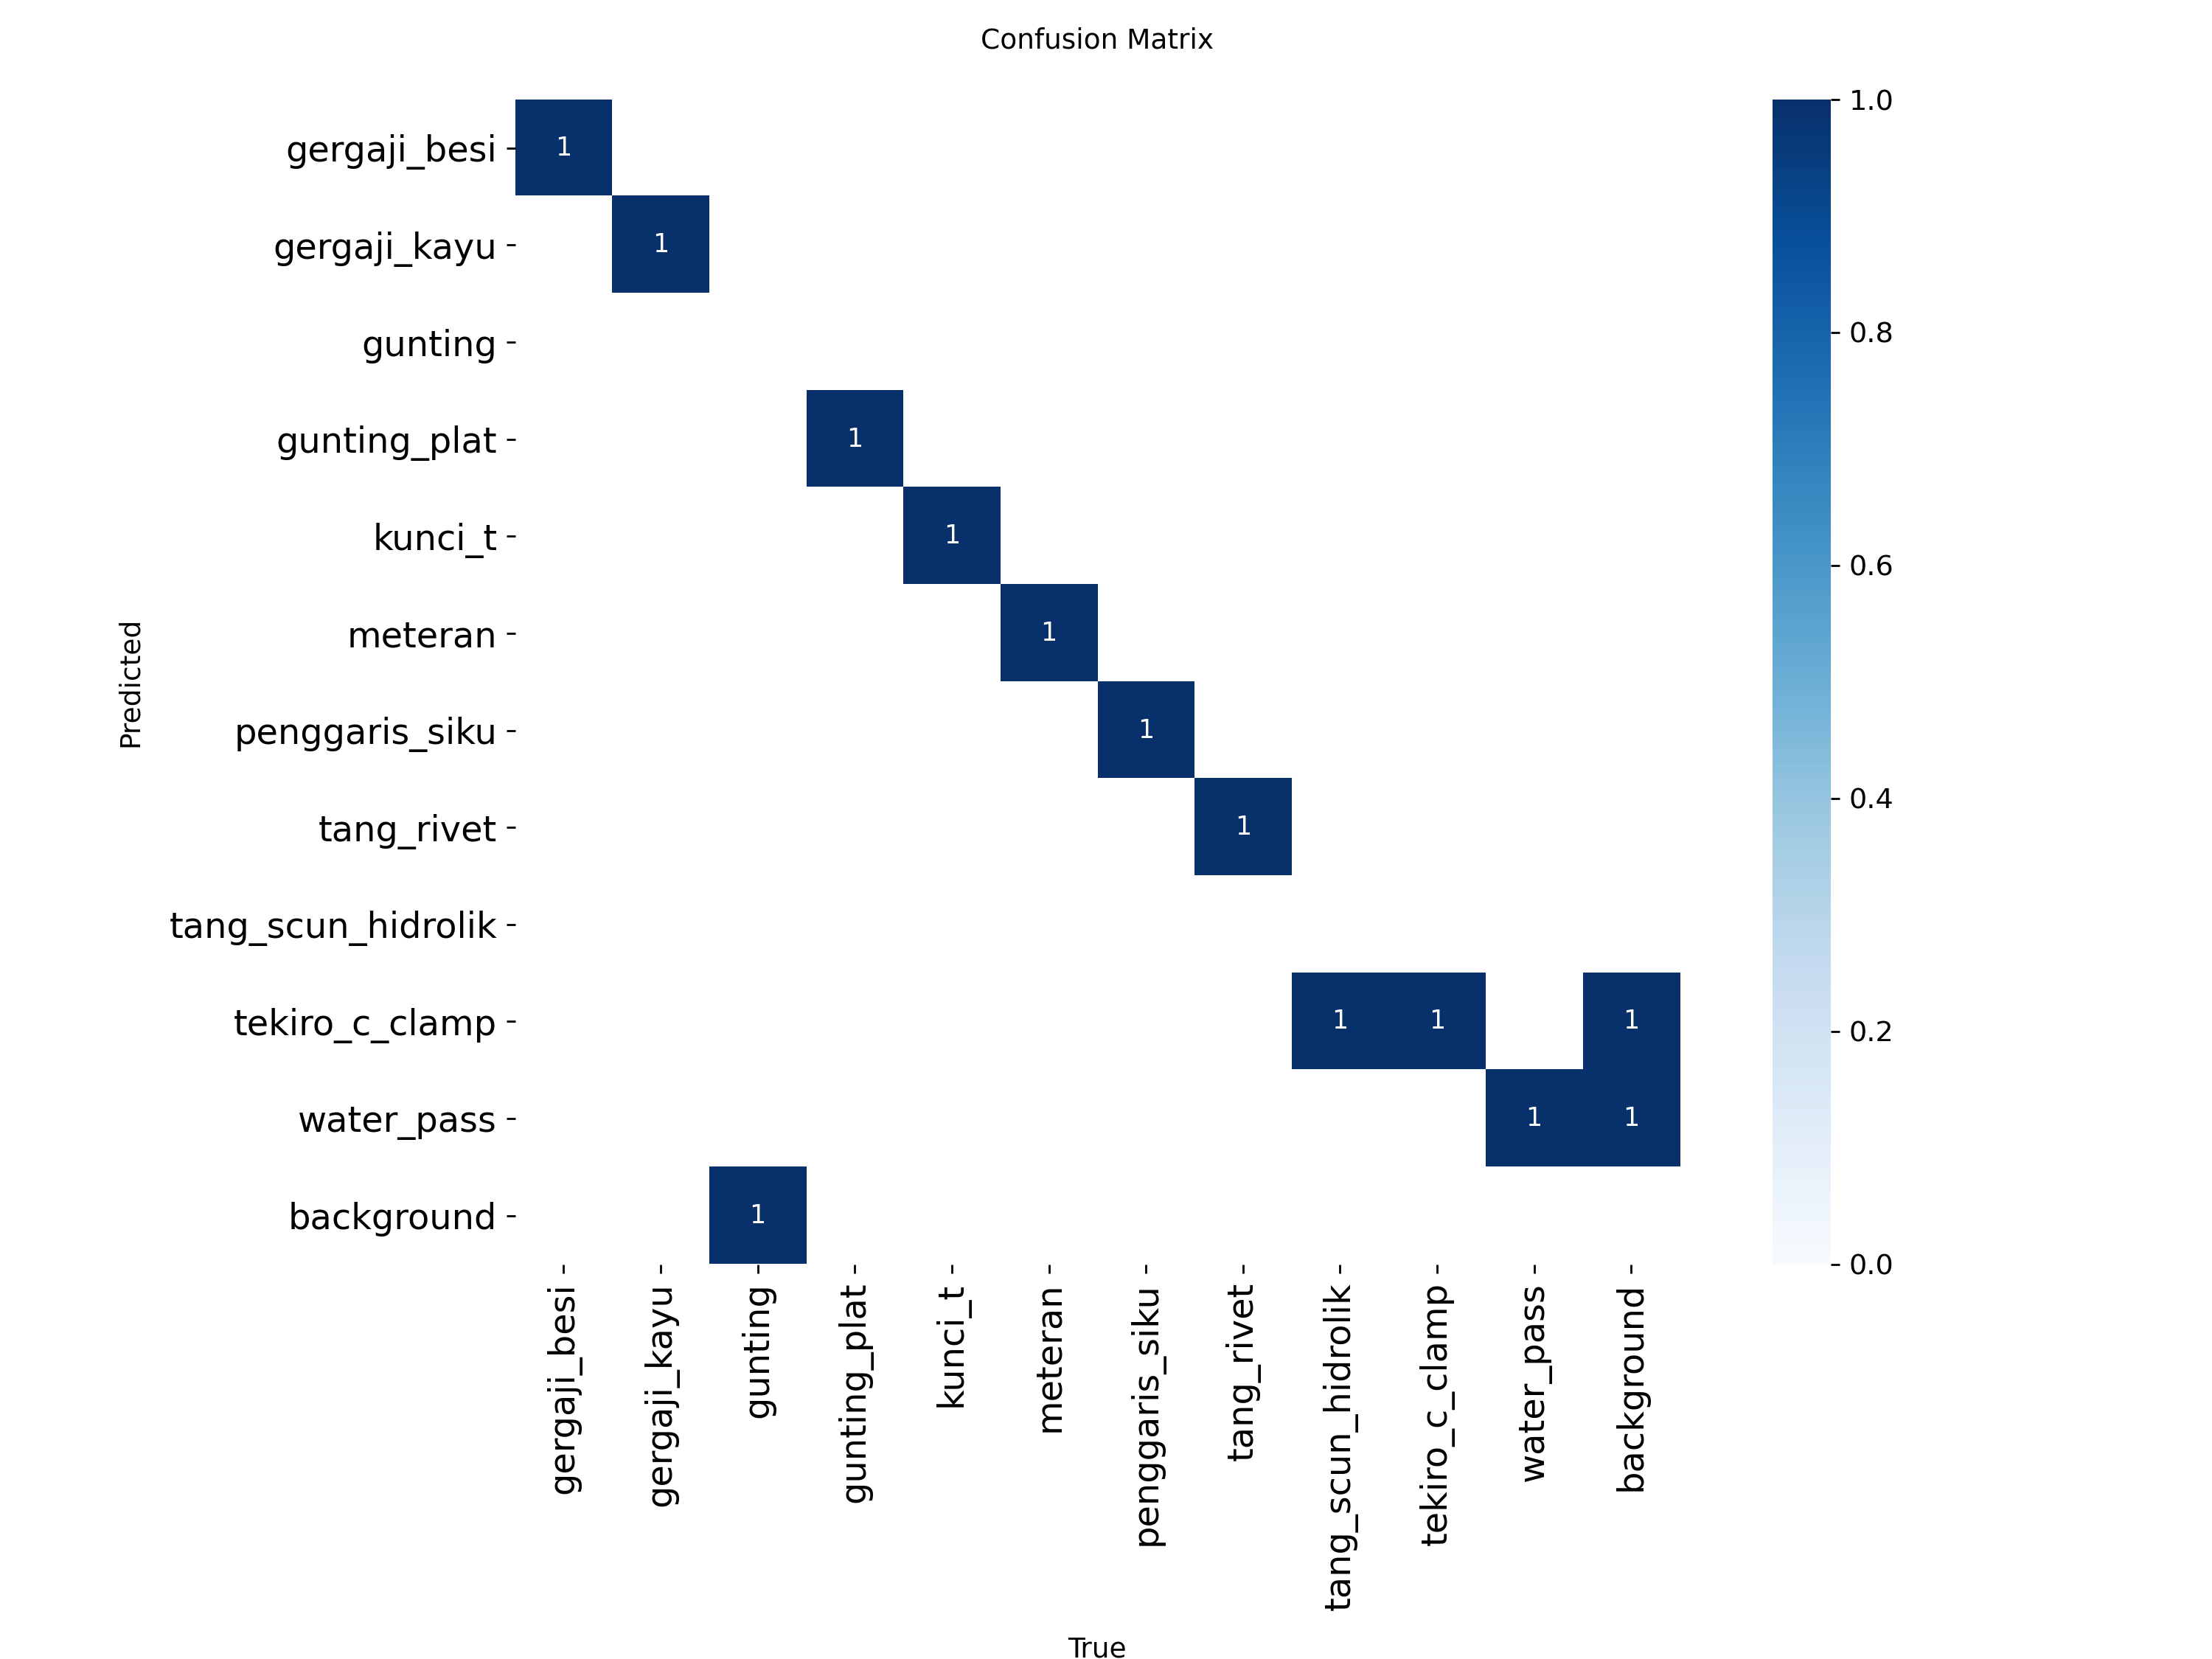

In [7]:
from IPython.display import Image, display

run = ROOT / "runs" / "colab"
print("best.pt:", (run / "weights" / "best.pt").exists())

for f in ["results.png", "confusion_matrix.png"]:
    p = run / f
    if p.exists():
        display(Image(str(p)))

# **Cell 8 - Test 1 Folder Gambar**

In [ ]:
model = YOLO(str(ROOT / "runs" / "colab" / "weights" / "best.pt"))
model.predict(
    source=str(ROOT / "test" / "images"),
    save=True,
    conf=0.5,
    project=str(ROOT / "runs"),
    name="predict",
)
print("Hasil:", ROOT / "runs" / "predict")


image 1/9 /content/drive/MyDrive/Detection Object - Yolo8/test/images/WIN_20261026_14_12_42_Pro_jpg.rf.c839c05dc2db3ca99afd18fdd837d0de.jpg: 640x640 (no detections), 11.7ms
image 2/9 /content/drive/MyDrive/Detection Object - Yolo8/test/images/WIN_20261026_14_29_28_Pro_jpg.rf.addb654904e722e22e79110c98207d48.jpg: 640x640 (no detections), 408.0ms
image 3/9 /content/drive/MyDrive/Detection Object - Yolo8/test/images/WIN_20261026_14_37_22_Pro_jpg.rf.ec6ec9c0eae2555813c438b50c2bfb20.jpg: 640x640 (no detections), 466.9ms
image 4/9 /content/drive/MyDrive/Detection Object - Yolo8/test/images/WIN_20261026_14_48_44_Pro_jpg.rf.1d43d3840b989b6210137f0b42f53656.jpg: 640x640 (no detections), 382.2ms
image 5/9 /content/drive/MyDrive/Detection Object - Yolo8/test/images/WIN_20261026_14_56_14_Pro_jpg.rf.1174716eb04aba19c5a2597e9f4001c4.jpg: 640x640 (no detections), 462.2ms
image 6/9 /content/drive/MyDrive/Detection Object - Yolo8/test/images/WIN_20261026_15_13_27_Pro_jpg.rf.ba4c8582f5f8a2ff9848cd9b429

# **Cell 9 - Cek gallery di Drive**

In [ ]:
ROOT = Path("/content/drive/MyDrive/Detection Object - Yolo8")
GALLERY = ROOT / "gallery"
print("Gallery ada:", GALLERY.exists())
for person in sorted(GALLERY.iterdir()):
  if person.is_dir():
    gallery_drive = len(list(person.glob("*")))
    print(f"  {person.name}: {gallery_drive} foto")

Gallery ada: True
  Aziz: 4 foto
  Ripal Rusandi: 4 foto
  Setiaji: 4 foto


# **Cell 10 - Install InsightFace**

In [ ]:
%pip install insightface -q
%pip uninstall -y onnxruntime -q
%pip install onnxruntime-gpu -q
print("InsightFace siap")

InsightFace siap


# **Cell 11 - Load model wajah (bukan pakai YOLO)**

In [ ]:
from insightface.app import FaceAnalysis

app = FaceAnalysis(name="buffalo_s")
app.prepare(ctx_id=0)
print("Model wajah loaded")

Model wajah loaded


# **Cell 12 - Enrollment (ini "daftar nama", bukan train 100 epoch)**

In [ ]:
import cv2
import numpy as np

names, vectors = [], []

for person_dir in sorted(GALLERY.iterdir()):
  if not person_dir.is_dir():
    continue
  embs = []
  for img_path in person_dir.glob("*"):
    img = cv2.imread(str(img_path))
    if img is None:
      continue
    faces = app.get(img)
    if not faces:
      print("Tidak ada wajah:", img_path)
      continue
    face = max(faces, key=lambda f: (f.bbox[2] - f.bbox[0]) * (f.bbox[3] - f.bbox[1]))
    embs.append(face.normed_embedding)
  if embs:
    names.append(person_dir.name)
    vectors.append(np.mean(embs, axis=0))
    print(person_dir.name, "ok,", len(embs), "foto")

vectors = np.stack(vectors)
vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)
out = str(ROOT / "gallery_embeddings.npz")
np.savez(out, names=np.array(names), embeddings=np.array(vectors))
print("Tersimpan:", out)
print("Orang:", names)

Aziz ok, 4 foto
Ripal Rusandi ok, 4 foto
Setiaji ok, 4 foto
Tersimpan: /content/drive/MyDrive/Detection Object - Yolo8/gallery_embeddings.npz
Orang: ['Aziz', 'Ripal Rusandi', 'Setiaji']


# **Cell 13 - Fungsi kenali nama**

In [ ]:
data = np.load(ROOT / "gallery_embeddings.npz", allow_pickle=True)
GALLERY_NAMES = data["names"]
GALLERY_EMB = data["embeddings"]
THRESH = 0.40

def identify(face):
  sim = GALLERY_EMB @ face.normed_embedding
  i = int(np.argmax(sim))
  score = float(sim[i])
  if score < THRESH:
    return "unknown", score
  return str(GALLERY_NAMES[i]), score

# **Cell 14 - Test 1 foto (alat + nama)**

In [ ]:
%pip install ultralytics -q
from ultralytics import YOLO
print("YOLO siap")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO siap


==== test_Setiaji.jpeg ok
Alat : -
Orang: [('unknown', 0.23293788731098175)]


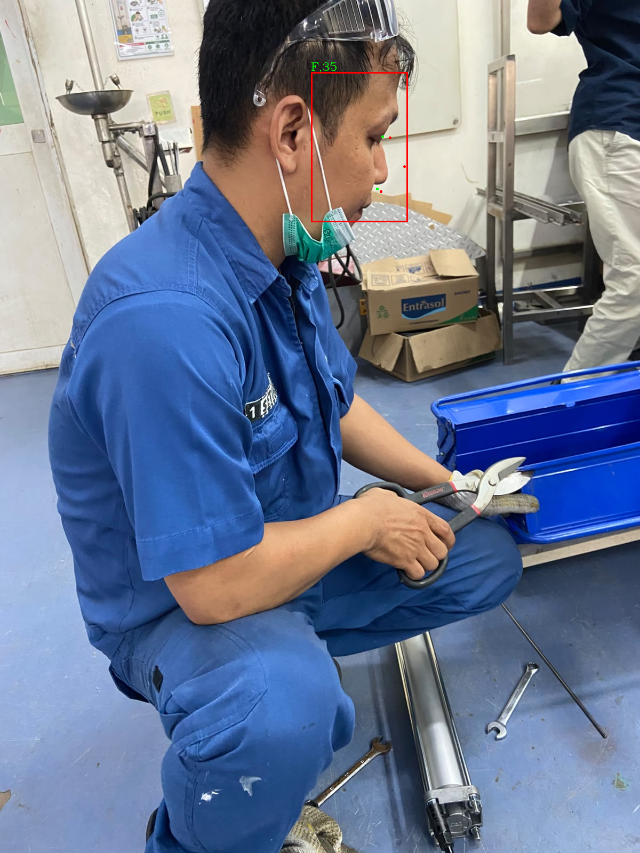

==== test_Ryvan.jpeg ok
Alat : -
Orang: [('unknown', 0.152414932847023)]


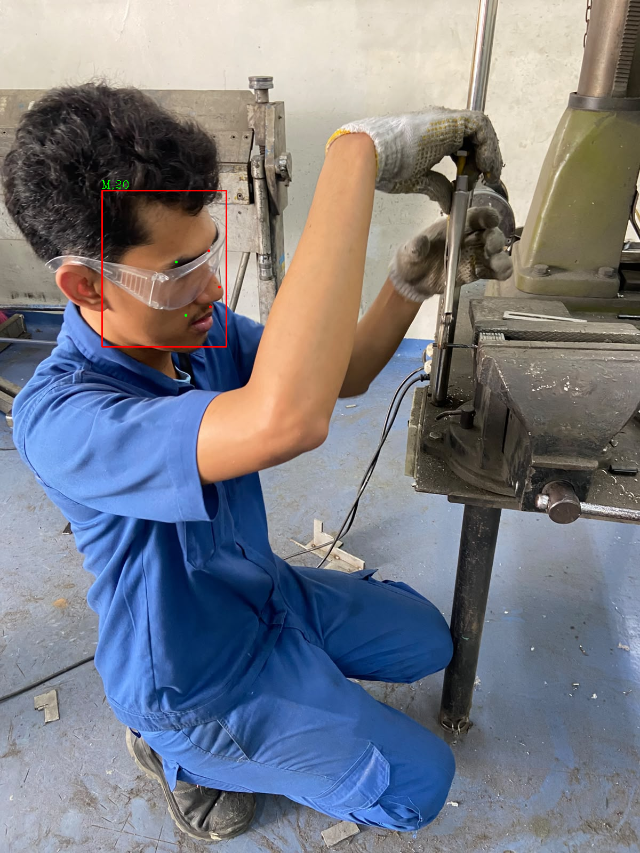

==== test_Ripal.jpeg ok
Alat : -
Orang: [('Ripal Rusandi', 0.898995041847229)]


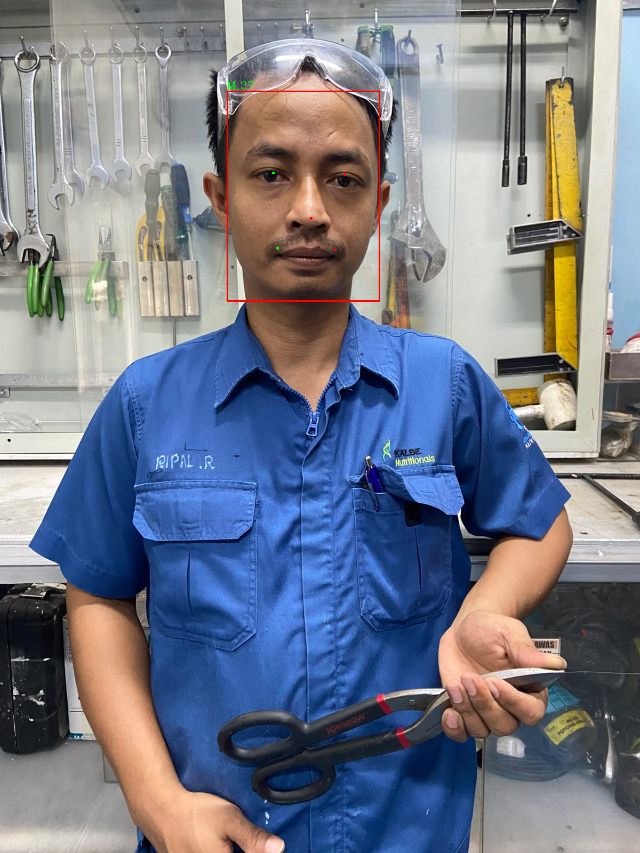

==== test_Aziz.jpeg ok
Alat : -
Orang: [('Aziz', 0.9242550730705261)]


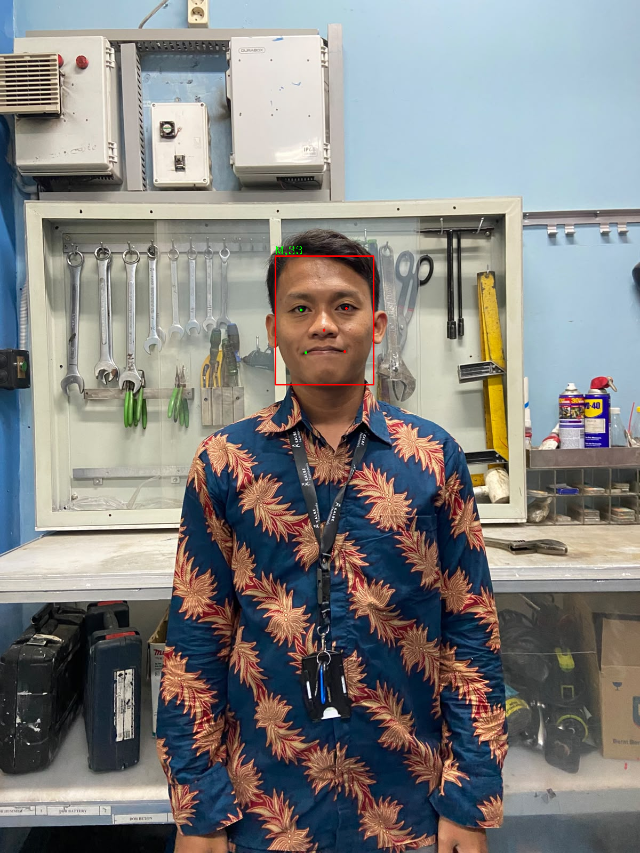

In [ ]:
from google.colab.patches import cv2_imshow
import cv2

yolo = YOLO(str(ROOT / "runs" / "colab" / "weights" / "best.pt"))

def tampil(img, lebar=640):
    h, w = img.shape[:2]
    if w > lebar:
        img = cv2.resize(img, (lebar, int(h * lebar / w)))
    cv2_imshow(img)

for nama in ["test_Setiaji.jpeg", "test_Ryvan.jpeg", "test_Ripal.jpeg", "test_Aziz.jpeg"]:
    path = ROOT / "teknisi" / nama
    img = cv2.imread(str(path))
    print("====", path.name, "ok" if img is not None else "GAGAL")
    if img is None:
        continue

    tools = yolo.predict(img, conf=0.5, verbose=False)[0]
    tool_names = [tools.names[int(c)] for c in tools.boxes.cls] if tools.boxes else []
    faces = app.get(img)
    people = [identify(f) for f in faces]

    print("Alat :", tool_names or "-")
    print("Orang:", people or "-")
    drawn = tools.plot()
    drawn = app.draw_on(drawn, faces)
    tampil(drawn, lebar=640)